# 30 — Targeted regional FX-only robustness

Keep **constant world/US/national-local prices, time-varying national/other FX prices, corrected
five-series FX means and zero equity alphas**. Compare **Poland, Czechia, Romania, Sweden and Hungary**
in **USD/EUR**, under **scalar and diagonal BEKK**, on the same frozen **October 2014–September
2026 (144 months)**. Use the existing **Python 3 (base)** kernel. Run notebook 29 first.

Fix the sensitivity set before fitting. No fetching, new observations, return interpolation, new
kernel or source edits. Calendar weights select joint likelihood terms **after** the full observed
state recursion. The small [regional_fx_robustness.py](regional_fx_robustness.py) wrapper reuses the
existing pricing filter, bounds and inference gates. Earlier research outputs remain pinned.

In [1]:
# Fixed common sample; adjustable numerical and diagnostic controls.
START_DYNAMICS = [(0.05, 0.90), (0.10, 0.70)]
MAX_ITER = 3000
MAX_ITER_OVERRIDES = {}
TEST_LAGS = 12
HAC_LAGS = (0, 3, 6, 12)
REUSE_FITS = True
MODEL_VERSION = "regional_targeted_fx_v1"
WORLD_INSTRUMENTS = ["short_rate_change_lag1_pp", "term_spread_change_lag1_pp", "credit_spread_lag1_pp"]
VARIANTS = ["baseline", "lag3", "gap_level", "no_regime", "no_US_CPI", "CPI_terms0", "block_2020", "block_2022_23"]
BLOCKS = {"block_2020": ("2020-01", "2020-12"), "block_2022_23": ("2022-01", "2023-12")}
PREVIOUS_MANIFEST_SHA = "357c7e237336d8a288eb30a7ef22cb5d488aa3a1926a492bcbe990d566c3c113"
LOCK_HASHES = {
    "regional_dataset_inputs.json": "0ceeef569dc4513d8534faf346509b22245db7ebff63abeb77044fc1474be208",
    "research_synthesis_inputs.json": "4fc2f36215746dd0ad0fef3ac41d8953f4abc6f1a3a36b526813437a26f081ee",
}

from pathlib import Path
from io import BytesIO
import hashlib, importlib, importlib.metadata, json, os, platform, sys
ROOT = Path.cwd()
os.environ.setdefault("MPLCONFIGDIR", str(ROOT/".cache"/"matplotlib"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, chi2
from packaging.version import Version
versions = {p: importlib.metadata.version(p) for p in
            ["numpy", "pandas", "scipy", "statsmodels", "matplotlib", "ipykernel"]}
if Version(versions["statsmodels"]) < Version("0.15.0"):
    raise RuntimeError("Use the base environment already used for notebooks 20–22 (statsmodels 0.15.0 or later).")
if "statsmodels" in sys.modules and sys.modules["statsmodels"].__version__ != versions["statsmodels"]:
    raise RuntimeError("Restart the existing base kernel to discard stale statsmodels imports.")
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.multitest import multipletests
from IPython.display import display, Markdown
import pricing_robustness as core
importlib.reload(core)
import regional_local_pricing as engine
importlib.reload(engine)
import regional_fx_robustness as stress
importlib.reload(stress)
import warnings
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.outliers_influence import variance_inflation_factor

NAMES = {"PL": "Poland", "CZ": "Czechia", "RO": "Romania", "SE": "Sweden", "HU": "Hungary"}
LOCAL_CURRENCIES = {"PL": "PLN", "CZ": "CZK", "RO": "RON", "SE": "SEK", "HU": "HUF"}
COUNTRY_ORDER, CURRENCIES, COVARIANCES = ["HU", "PL", "CZ", "RO", "SE"], ["USD", "EUR"], ["scalar", "diagonal"]
ASSETS = ["World", "US", "National", "National FX", "Other FX"]
COLORS = {"PL": "#285f9e", "CZ": "#2a8a70", "RO": "#9469ad", "SE": "#b77d13", "HU": "#c4483b"}
PREVIOUS = ROOT/"output/29_regional_time_varying_FX_only/2014-10_2026-09/fx_only_606736e5"
assert len(set(VARIANTS)) == len(VARIANTS) and VARIANTS[0] == "baseline"
assert set(VARIANTS) == {"baseline", "lag3", "gap_level", "no_regime", "no_US_CPI", "CPI_terms0", *BLOCKS}
spec = {"variants": VARIANTS, "blocks": BLOCKS, "weights": "joint likelihood only; full calendar recursion",
        "equity_alphas": "fixed zero", "previous_manifest_sha256": PREVIOUS_MANIFEST_SHA}
instrument_id = hashlib.sha256(json.dumps(spec, sort_keys=True).encode()).hexdigest()[:8]
OUT = ROOT/"output/30_regional_FX_targeted_robustness/2014-10_2026-09"/f"targeted_{instrument_id}"
OUT.mkdir(parents=True, exist_ok=True)
def sha(raw): return hashlib.sha256(raw).hexdigest()
engine_hashes = {name: sha((ROOT/name).read_bytes()) for name in
    ["regional_fx_robustness.py", "regional_pricing_errors.py", "regional_local_pricing.py", "regional_fx_price_variation.py", "regional_world_pricing.py", "regional_currency_pricing.py", "pricing_robustness.py", "regional_pricing_baseline.py", "regional_covariance_sensitivity.py"]}
assert 2 <= TEST_LAGS <= 24 and tuple(HAC_LAGS) == (0, 3, 6, 12)
assert all(a > 0 and b > 0 and a+b < 1 for a, b in START_DYNAMICS)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .18})
pd.set_option("display.max_columns", 14)
print("Python:", sys.executable)
print("Packages:", versions)
print("Zero-alpha pricing engine SHA-256:", engine_hashes["regional_local_pricing.py"])

Python: /Users/lajosgalambos/miniconda3/bin/python
Packages: {'numpy': '2.4.4', 'pandas': '3.0.2', 'scipy': '1.17.1', 'statsmodels': '0.15.0', 'matplotlib': '3.10.8', 'ipykernel': '7.2.0'}
Zero-alpha pricing engine SHA-256: f19326824d977a250770428f9951223e8219d5fdebb63b07aeff9e462757b2fb


## 1. Verify the frozen data and references

Verify notebook 29's manifest and all inherited files and engine hashes. Keep ten five-series input
systems and exact currency-conversion identities. Hungary uses the regional common sample, not its
longer history. The 20 FX-only references include notebook 29's numerical flags; a missing p-value
never becomes an accepted null in this notebook.

In [2]:
def verify_inputs():
    raw = (PREVIOUS/"estimation_manifest.json").read_bytes()
    if sha(raw) != PREVIOUS_MANIFEST_SHA: raise ValueError("Notebook-29 manifest changed.")
    previous = json.loads(raw)
    assert previous["input_locks"] == LOCK_HASHES
    assert (previous["first"], previous["last"], previous["observations_per_fit"]) == ("2014-10", "2026-09", 144)
    expected = previous["input_file_hashes"].copy()
    for name, checksum in previous["outputs"].items():
        expected[(PREVIOUS/name).relative_to(ROOT).as_posix()] = checksum
    expected[(PREVIOUS/"estimation_manifest.json").relative_to(ROOT).as_posix()] = PREVIOUS_MANIFEST_SHA
    expected.update(previous["engines"])
    locks = {}
    for name, checksum in LOCK_HASHES.items():
        content = (ROOT/name).read_bytes()
        if sha(content) != checksum: raise ValueError(f"Changed input lock: {name}")
        locks[name] = json.loads(content)
    for path, checksum in expected.items():
        if sha((ROOT/path).read_bytes()) != checksum: raise ValueError(f"Changed frozen input: {path}")
    regional = locks["regional_dataset_inputs.json"]
    assert sha((ROOT/regional["root"]/"manifest.json").read_bytes()) == regional["manifest_sha256"]
    return locks, expected

locks, input_hashes = verify_inputs()
regional = locks["regional_dataset_inputs.json"]
assert (regional["common_start"], regional["common_end"], regional["common_months"]) == ("2014-10", "2026-09", 144)
months = pd.period_range("2014-10", "2026-09", freq="M", name="month")
frames, samples, scales, source_hashes, audit_rows = {}, {}, {}, {}, []
for country in COUNTRY_ORDER:
    for currency in CURRENCIES:
        path = ROOT/regional["root"]/"common"/f"{country}_{currency}.csv"
        raw = path.read_bytes()
        assert sha(raw) == input_hashes[path.relative_to(ROOT).as_posix()]
        d = pd.read_csv(BytesIO(raw), index_col=0, float_precision="round_trip")
        d.index = pd.PeriodIndex(d.index, freq="M", name="month")
        assert d.index.equals(months) and np.isfinite(d.to_numpy()).all() and d.flag_known_index_backcast.sum() == 0
        for asset in ["world", "us", "local"]:
            np.testing.assert_allclose(d[f"rx_{asset}"], d[f"r_{asset}"]-d.rf, atol=1e-12, rtol=0)
        y = d[["rx_world", "rx_us", "rx_local", "fx_local", "fx_other"]].to_numpy()*100
        scale = y.std(axis=0, ddof=1)
        correlation = np.cov(y, rowvar=False)/np.outer(scale, scale)
        assert (scale > 0).all() and np.linalg.eigvalsh(correlation).min() > 0 and np.linalg.matrix_rank(y-y.mean(axis=0)) == 5
        key = (country, currency)
        frames[key], samples[key], scales[key], source_hashes[key] = d, y, scale, sha(raw)
        np.testing.assert_array_equal(y[:, [0, 1, 4]], samples[("HU", currency)][:, [0, 1, 4]])
        audit_rows.append({"country": country, "name": NAMES[country], "perspective": currency,
            "first": str(months[0]), "last": str(months[-1]), "months": len(y), "rank": 5,
            "min_correlation_eigenvalue": np.linalg.eigvalsh(correlation).min(), "correlation_condition": np.linalg.cond(correlation),
            "national_FX_sd_pp": scale[3], "national_FX_currency": LOCAL_CURRENCIES[country],
            "other_FX_currency": "EUR" if currency == "USD" else "USD"})
transform = np.eye(5)
transform[:3, 4], transform[3, 4], transform[4, 4] = -1., -1., -1.
for country in COUNTRY_ORDER:
    converted = samples[(country, "USD")]@transform.T
    converted[:, :3] += ((frames[(country, "USD")].rf-frames[(country, "EUR")].rf)*100).to_numpy()[:, None]
    np.testing.assert_allclose(converted, samples[(country, "EUR")], atol=1e-10, rtol=0)
input_audit = pd.DataFrame(audit_rows)
display(input_audit.set_index(["name", "perspective"])[["months", "rank", "correlation_condition", "national_FX_sd_pp", "other_FX_currency"]].round(4))
print("Verified", len(input_hashes), "protected files and all ten five-series input systems.")

months  rank  correlation_condition  national_FX_sd_pp  \
name    perspective                                                           
Hungary USD             144     5               177.8975             3.0207   
        EUR             144     5               123.6042             1.7874   
Poland  USD             144     5               196.7334             2.9611   
        EUR             144     5               135.7310             1.4953   
Czechia USD             144     5               218.7463             2.6464   
        EUR             144     5               152.3439             1.1305   
Romania USD             144     5               168.0376             2.1759   
        EUR             144     5               110.8968             0.5283   
Sweden  USD             144     5               242.4797             2.9674   
        EUR             144     5               174.9449             1.7097   

                    other_FX_currency  
name    perspective                    
Hungary USD                       EUR  
        EUR                       USD  
Poland  USD                       EUR  
        EUR                       USD  
Czechia USD                       EUR  
        EUR                       USD  
Romania USD                       EUR  
        EUR                       USD  
Sweden  USD                       EUR  
        EUR                       USD

Verified 1772 protected files and all ten five-series input systems.


## 2. Predeclare and audit the targeted checks

| Check | Change from notebook 29's FX-only baseline |
|---|---|
| `lag3` | Both FX inflation conditioners lag 3 instead of 2; use frozen pre-sample history |
| `gap_level` | National inflation-gap level replaces its change at lag 2; exploratory |
| `no_regime` | Remove the varying national regime predictor; only Czechia has one |
| `no_US_CPI` | Remove direct FX-price inflation predictors involving US CPI throughout the sample |
| `CPI_terms0` | Zero joint likelihood weight where baseline FX predictors use the carried annual US rate |
| `block_2020` | Zero joint likelihood weights during 2020 |
| `block_2022_23` | Zero joint likelihood weights during 2022–23 |

The 2008–09 check from Hungarian notebook 14 is **outside this common sample** and recorded as
inapplicable. `no_regime` is an exact baseline alias in PL/RO/SE/HU: retain it for transparency, reuse
its estimate/inference and do not count it as an independent robustness check.

Rebuild inflation features from sealed raw CPI/HICP history; do not shift the 144-row export and
drop its first month. Repeat only the inherited October 2025 **annual-US-inflation-rate** carry;
never fill a CPI index or return. Keep already-lagged global predictors and all retained baseline
columns exactly as archived. Normalize changed inflation predictors on all 144 months, including
weighted scenarios. Check full/scored rank, conditioning, VIF, leverage and inflation persistence
before fitting. A longer lag is a timing sensitivity; the frozen historical series can contain revisions.

In EUR, removing US CPI leaves the national EA-minus-country gap intact and removes the other-FX
US/EA term. In USD it removes both FX inflation terms. This changes the available information across
the whole sample. `CPI_terms0` is a complementary influence check, not removal of propagated shocks.

In [3]:
source_conditioning = pd.read_csv(PREVIOUS/"conditioning_design.csv", float_precision="round_trip").query("stage == 5")
source_quality = pd.read_csv(PREVIOUS/"inflation_quality_flags.csv").query("stage == 5")
source_inference = pd.read_csv(PREVIOUS/"inference_audit.csv").query("stage == 5")
base_designs, base_names = {}, {}
for key in samples:
    country, currency = key; base_designs[key], base_names[key] = {}, {}
    for factor in ["W", "H", "O", "L"]:
        g = source_conditioning.query("country == @country and perspective == @currency and factor == @factor")
        names = list(g.instrument.unique())
        assert all(g.loc[g.instrument.eq(n), "month"].tolist() == months.astype(str).tolist() for n in names)
        base_names[key][factor] = names
        base_designs[key][factor] = np.array(np.column_stack([g.loc[g.instrument.eq(n), "value"] for n in names]), order="F" if factor in ["H", "O"] else "C")
original_root = ROOT/locks["research_synthesis_inputs.json"]["snapshot"]
fred = pd.read_csv(original_root/"raw/fred.csv", index_col=0, float_precision="round_trip")
fred.index = pd.PeriodIndex(fred.index, freq="M")
fred = fred.reindex(pd.period_range(fred.index.min(), fred.index.max(), freq="M"))
rebuilt_global = pd.DataFrame({WORLD_INSTRUMENTS[0]: fred.TB3MS.diff().shift(1),
    WORLD_INSTRUMENTS[1]: (fred.GS10-fred.TB3MS).diff().shift(1), WORLD_INSTRUMENTS[2]: (fred.BAA-fred.AAA).shift(1)}).loc[months]
for d in frames.values(): np.testing.assert_allclose(d[WORLD_INSTRUMENTS], rebuilt_global, atol=1e-12, rtol=0)
def hicp(path):
    j = json.loads(path.read_text()); flat = np.full(np.prod(j["size"]), np.nan)
    assert j["id"] == ["freq", "unit", "coicop18", "geo", "time"] and j["size"][:3] == [1, 1, 1]
    for pos, value in j["value"].items(): flat[int(pos)] = value
    values = flat.reshape(j["size"])[0, 0, 0]
    geo, time = (j["dimension"][a]["category"]["index"] for a in ["geo", "time"])
    return pd.DataFrame({g: values[i] for g, i in geo.items()}, index=pd.PeriodIndex(sorted(time, key=time.get), freq="M"))
calendar = pd.period_range("1998-01", "2026-09", freq="M")
levels = pd.concat([hicp(original_root/"raw/eurostat_hicp.json"), hicp(ROOT/regional["root"]/"raw/national_hicp.json")], axis=1).reindex(calendar)
annual = levels.pct_change(12, fill_method=None)*100
us_raw = fred.CPIAUCNS.reindex(calendar).pct_change(12, fill_method=None)*100
us = us_raw.ffill(limit=1); carried = us_raw.isna() & us.notna()
assert list(carried[carried].index.astype(str)) == ["2025-10"]
designs, names_by, weights_by, quality_by = {}, {}, {}, {}
conditioning_rows, raw_rows, transform_rows, design_rows, vif_rows, inflation_rows, quality_rows, applicability_rows = [], [], [], [], [], [], [], []
for key, d in frames.items():
    country, currency = key
    national_gap = (us if currency == "USD" else annual.EA)-annual[country]
    other_gap = us-annual.EA if currency == "USD" else annual.EA-us
    for a, b in [(national_gap.shift(2), "inflation_gap_lag2_pp"), (national_gap.diff().shift(2), "inflation_gap_change_lag2_pp"), (other_gap.shift(2), "other_fx_gap_lag2_pp")]:
        np.testing.assert_allclose(a.loc[months], d[b], atol=1e-12, rtol=0)
    for variant in VARIANTS:
        tag = {"country": country, "perspective": currency, "variant": variant}; vk = (*key, variant)
        lag, form = (3 if variant == "lag3" else 2), ("level" if variant == "gap_level" else "change")
        hn = "national_"+form+("_lag3" if lag == 3 else ""); on = "other_level"+("_lag3" if lag == 3 else "")
        hraw, oraw = d[WORLD_INSTRUMENTS].copy(), d[WORLD_INSTRUMENTS].copy()
        hraw[hn] = (national_gap.diff() if form == "change" else national_gap).shift(lag).loc[months]
        oraw[on] = other_gap.shift(lag).loc[months]
        if "regime_indicator" in base_names[key]["H"] and variant != "no_regime": hraw["regime_indicator"] = d.regime_indicator
        hflag = (carried.shift(lag, fill_value=False) | (carried.shift(lag+1, fill_value=False) if form == "change" else False)).loc[months] & (currency == "USD")
        oflag = carried.shift(lag, fill_value=False).loc[months]
        if variant == "no_US_CPI":
            oraw = oraw.drop(columns=on); oflag = pd.Series(False, index=months)
            if currency == "USD": hraw = hraw.drop(columns=hn); hflag = pd.Series(False, index=months)
        w = np.ones(len(months))
        if variant == "CPI_terms0": w[(hflag | oflag).to_numpy()] = 0.
        if variant in BLOCKS:
            first, last = BLOCKS[variant]; w[(months >= first) & (months <= last)] = 0.
        designs[vk], names_by[vk] = {"W": np.ones((len(months), 1)), "L": np.ones((len(months), 1))}, {"W": ["constant"], "L": ["constant"]}
        for factor, raw in [("H", hraw), ("O", oraw)]:
            center, spread = raw.mean(), raw.std(ddof=1)
            assert np.isfinite(raw.to_numpy()).all() and spread.gt(0).all()
            nn = ["constant"]+list(raw.columns); D = np.c_[np.ones(len(months)), ((raw-center)/spread).to_numpy()]
            for j, name in enumerate(nn):
                if name in base_names[key][factor]:
                    old = base_designs[key][factor][:, base_names[key][factor].index(name)]
                    np.testing.assert_allclose(D[:, j], old, atol=1e-12, rtol=0); D[:, j] = old
            D = np.array(D, order="F")
            assert np.linalg.matrix_rank(D) == D.shape[1] and np.linalg.matrix_rank(D[w > 0]) == D.shape[1]
            designs[vk][factor], names_by[vk][factor] = D, nn
            leverage = np.sum(np.linalg.qr(D, mode="reduced")[0]**2, axis=1)
            scored_leverage = np.sum(np.linalg.qr(D[w > 0], mode="reduced")[0]**2, axis=1)
            design_rows.append({**tag, "factor": factor, "columns": D.shape[1], "rank_full": np.linalg.matrix_rank(D), "rank_scored": np.linalg.matrix_rank(D[w > 0]),
                "condition_full": np.linalg.cond(D), "condition_scored": np.linalg.cond(D[w > 0]), "max_leverage_full": leverage.max(),
                "max_leverage_month": str(months[leverage.argmax()]), "max_leverage_scored": scored_leverage.max(), "state_months": len(months), "scored_months": int(w.sum()), "design_sha256": sha(D.tobytes())})
            vif_rows.extend({**tag, "factor": factor, "instrument": n, "VIF_full": variance_inflation_factor(D, j), "VIF_scored": variance_inflation_factor(D[w > 0], j)} for j, n in enumerate(nn) if j)
            transform_rows.extend({**tag, "factor": factor, "instrument": n, "mean": center[n], "sd_ddof1": spread[n]} for n in raw)
            conditioning_rows.extend({**tag, "factor": factor, "instrument": n, "month": str(m), "value": D[t, j]} for j, n in enumerate(nn) for t, m in enumerate(months))
            raw_rows.extend({**tag, "factor": factor, "instrument": n, "month": str(m), "value": raw[n].iloc[t]} for n in raw for t, m in enumerate(months))
            if variant in ["baseline", "lag3", "gap_level"]:
                for n in raw.columns.difference(WORLD_INSTRUMENTS+["regime_indicator"]):
                    v = raw[n]; a = adfuller(v, maxlag=12, regression="c", autolag="AIC", result_object=False)
                    with warnings.catch_warnings(record=True) as caught:
                        warnings.simplefilter("always"); k = kpss(v, regression="c", nlags="auto", result_object=False)
                    bound = (">=" if k[1] >= .1 else "<=") if caught else ""
                    inflation_rows.append({**tag, "factor": factor, "instrument": n, "AR1": v.autocorr(), "ADF_p_raw": a[1], "KPSS_p_report": f"{bound}{k[1]:.5g}"})
        # Preserve the engine's W,H,O,L parameter order, independently of dict creation above.
        designs[vk] = {a: designs[vk][a] for a in ["W", "H", "O", "L"]}
        names_by[vk] = {a: names_by[vk][a] for a in ["W", "H", "O", "L"]}
        weights_by[vk] = w
        quality_by[vk] = pd.DataFrame({"national_uses_carried_US": hflag, "other_uses_carried_US": oflag}, index=months)
        quality_rows.extend({**tag, "month": str(m), "national_uses_carried_US": bool(hflag.iloc[t]), "other_uses_carried_US": bool(oflag.iloc[t]), "likelihood_weight": w[t]} for t, m in enumerate(months))
        alias = variant != "baseline" and all(np.array_equal(designs[vk][a], base_designs[key][a]) and names_by[vk][a] == base_names[key][a] for a in designs[vk]) and np.all(w == 1)
        applicability_rows.append({**tag, "applicable": not alias, "baseline_alias": alias, "affected_likelihood_months": int((w == 0).sum()),
            "reason": "baseline reference" if variant == "baseline" else ("no varying regime column; exact baseline alias" if alias else "active sensitivity")})
    flags = source_quality.query("country == @country and perspective == @currency")
    for n in ["national_uses_carried_US", "other_uses_carried_US"]: np.testing.assert_array_equal(quality_by[(*key, "baseline")][n], flags[n])
    applicability_rows.append({"country": country, "perspective": currency, "variant": "block_2008_09", "applicable": False, "baseline_alias": False,
        "affected_likelihood_months": 0, "reason": "outside 2014-10 to 2026-09; not estimated"})
conditioning, raw_features, normalizers, design_audit, vifs, inflation_audit, quality_flags, applicability = map(pd.DataFrame,
    [conditioning_rows, raw_rows, transform_rows, design_rows, vif_rows, inflation_rows, quality_rows, applicability_rows])
display(design_audit.groupby(["variant", "factor"])[["rank_full", "rank_scored", "condition_scored", "max_leverage_full"]].agg(["min", "max"]).round(4))
display(inflation_audit.set_index(["country", "perspective", "variant", "factor"])[["AR1", "ADF_p_raw", "KPSS_p_report"]].round(4))
display(applicability.query("not applicable"))

rank_full     rank_scored     condition_scored          \
                           min max         min max              min     max   
variant       factor                                                          
CPI_terms0    H              5   6           5   6           1.7993  1.9485   
              O              5   5           5   5           2.0612  2.0701   
baseline      H              5   6           5   6           1.8022  1.9625   
              O              5   5           5   5           2.0729  2.0729   
block_2020    H              5   6           5   6           1.8638  2.2333   
              O              5   5           5   5           2.1222  2.1222   
block_2022_23 H              5   6           5   6           1.9511  2.2847   
              O              5   5           5   5           2.1790  2.1790   
gap_level     H              5   6           5   6           1.8094  2.7180   
              O              5   5           5   5           2.0729  2.0729   
lag3          H              5   6           5   6           1.8038  1.9481   
              O              5   5           5   5           1.9784  1.9784   
no_US_CPI     H              4   6           4   6           1.7991  1.9156   
              O              4   4           4   4           1.7991  1.7991   
no_regime     H              5   5           5   5           1.8022  1.9625   
              O              5   5           5   5           2.0729  2.0729   

                     max_leverage_full          
                                   min     max  
variant       factor                            
CPI_terms0    H                 0.4065  0.4498  
              O                 0.4080  0.4080  
baseline      H                 0.4065  0.4498  
              O                 0.4080  0.4080  
block_2020    H                 0.4065  0.4498  
              O                 0.4080  0.4080  
block_2022_23 H                 0.4065  0.4498  
              O                 0.4080  0.4080  
gap_level     H                 0.4080  0.4638  
              O                 0.4080  0.4080  
lag3          H                 0.4066  0.4590  
              O                 0.4065  0.4065  
no_US_CPI     H                 0.4065  0.4314  
              O                 0.4065  0.4065  
no_regime     H                 0.4065  0.4498  
              O                 0.4080  0.4080

AR1  ADF_p_raw KPSS_p_report
country perspective variant   factor                                 
HU      USD         baseline  H       0.7581     0.0042         >=0.1
                              O       0.9430     0.0873         >=0.1
                    lag3      H       0.7599     0.0035         >=0.1
                              O       0.9434     0.0892         >=0.1
                    gap_level H       0.9834     0.0005      0.098254
                              O       0.9430     0.0873         >=0.1
        EUR         baseline  H       0.5619     0.0008         >=0.1
                              O       0.9430     0.0873         >=0.1
                    lag3      H       0.5620     0.0006         >=0.1
                              O       0.9434     0.0892         >=0.1
                    gap_level H       0.9791     0.6173      0.069291
                              O       0.9430     0.0873         >=0.1
PL      USD         baseline  H       0.4913     0.0000         >=0.1
                              O       0.9430     0.0873         >=0.1
                    lag3      H       0.4884     0.0000         >=0.1
                              O       0.9434     0.0892         >=0.1
                    gap_level H       0.9810     0.5830      0.024662
                              O       0.9430     0.0873         >=0.1
        EUR         baseline  H       0.2775     0.0031         >=0.1
                              O       0.9430     0.0873         >=0.1
                    lag3      H       0.2782     0.0026         >=0.1
                              O       0.9434     0.0892         >=0.1
                    gap_level H       0.9783     0.6096        <=0.01
                              O       0.9430     0.0873         >=0.1
CZ      USD         baseline  H       0.1929     0.0002         >=0.1
                              O       0.9430     0.0873         >=0.1
                    lag3      H       0.1954     0.0003         >=0.1
                              O       0.9434     0.0892         >=0.1
                    gap_level H       0.9696     0.2321         >=0.1
                              O       0.9430     0.0873         >=0.1
        EUR         baseline  H       0.0389     0.0084         >=0.1
                              O       0.9430     0.0873         >=0.1
                    lag3      H       0.0401     0.0087         >=0.1
                              O       0.9434     0.0892         >=0.1
                    gap_level H       0.9456     0.2169         >=0.1
                              O       0.9430     0.0873         >=0.1
RO      USD         baseline  H       0.2306     0.0032         >=0.1
                              O       0.9430     0.0873         >=0.1
                    lag3      H       0.2354     0.0046         >=0.1
                              O       0.9434     0.0892         >=0.1
                    gap_level H       0.9745     0.3992        <=0.01
                              O       0.9430     0.0873         >=0.1
        EUR         baseline  H       0.0366     0.0000         >=0.1
                              O       0.9430     0.0873         >=0.1
                    lag3      H       0.0310     0.0000         >=0.1
                              O       0.9434     0.0892         >=0.1
                    gap_level H       0.9680     0.6865        <=0.01
                              O       0.9430     0.0873         >=0.1
SE      USD         baseline  H       0.0764     0.0000         >=0.1
                              O       0.9430     0.0873         >=0.1
                    lag3      H       0.0826     0.0000         >=0.1
                              O       0.9434     0.0892         >=0.1
                    gap_level H       0.9132     0.0757         >=0.1
                              O       0.9430     0.0873         >=0.1
        EUR         baseline  H      -0.1906     0.0000         >=0.1
                              O       0.9430     0.

,country,perspective,variant,applicable,baseline_alias,affected_likelihood_months,reason
3,HU,USD,no_regime,False,True,0,no varying regime column; exact baseline alias
8,HU,USD,block_2008_09,False,False,0,outside 2014-10 to 2026-09; not estimated
12,HU,EUR,no_regime,False,True,0,no varying regime column; exact baseline alias
17,HU,EUR,block_2008_09,False,False,0,outside 2014-10 to 2026-09; not estimated
21,PL,USD,no_regime,False,True,0,no varying regime column; exact baseline alias
26,PL,USD,block_2008_09,False,False,0,outside 2014-10 to 2026-09; not estimated
30,PL,EUR,no_regime,False,True,0,no varying regime column; exact baseline alias
35,PL,EUR,block_2008_09,False,False,0,outside 2014-10 to 2026-09; not estimated
44,CZ,USD,block_2008_09,False,False,0,outside 2014-10 to 2026-09; not estimated
53,CZ,EUR,block_2008_09,False,False,0,outside 2014-10 to 2026-09; not estimated


## 3. Verify weighted derivatives and the unchanged state recursion

For the joint five-series negative log likelihood $\ell_t$ and fixed $w_t\in\{0,1\}$:

$$\boxed{Q_T(\theta)=T^{-1}\sum_{t=1}^{T}w_t\ell_t(\theta),\qquad T=144.}$$

The filter and derivatives use **all 144 observations before weighting**. Zero-weight observations
still affect later conditional means and covariances. Keep zero-score rows in their original calendar
positions for Hessian/HAC calculations. Do not concatenate scored dates. All-ones weights must
reproduce notebook 29's filter, objective, scores and robust covariance. No crisis-free-sample claim
is made. Weighted scenarios retain 142 USD / 143 EUR CPI-scored months, 132 for 2020 and 120 for 2022–23.

In [4]:
def make_case(key, covariance, variant):
    vk = (*key, variant); country, currency = key
    alias = bool(applicability.query("country == @country and perspective == @currency and variant == @variant").baseline_alias.iloc[0])
    return {"country": country, "perspective": currency, "covariance": covariance, "variant": variant,
        "id": f"{country}_{currency}_{covariance}_{variant}", "y": samples[key], "scales": scales[key],
        "designs": designs[vk], "names": names_by[vk], "weights": weights_by[vk], "alias": alias}
def args(case): return case["y"], case["designs"], case["scales"], case["covariance"], case["weights"]
def filter_case(theta, case): return engine.filter_model(theta, case["y"], case["designs"], case["scales"], True, case["covariance"])
def price_count(case): return 5+sum(d.shape[1]-1 for d in case["designs"].values())
def map_theta(theta, old, new):
    assert old["covariance"] == new["covariance"]
    result = np.r_[np.zeros(price_count(new)), theta[price_count(old):]]; result[1] = theta[1]
    oi, ni = engine.price_indices(old["designs"], True), engine.price_indices(new["designs"], True)
    for a in new["designs"]:
        for j, n in zip(ni[a], new["names"][a]):
            if n in old["names"][a]: result[j] = theta[oi[a][old["names"][a].index(n)]]
    return result
cases = {(*key, cov, variant): make_case(key, cov, variant) for key in samples for cov in COVARIANCES for variant in VARIANTS}
references, reference_rows, check_rows = {}, [], []
for key, case in cases.items():
    country, currency, cov, variant = key
    if variant == "baseline":
        path = PREVIOUS/f"parameters_{country}_{currency}_{cov}_FX.npz"
        assert sha(path.read_bytes()) == input_hashes[path.relative_to(ROOT).as_posix()]
        with np.load(path, allow_pickle=False) as saved:
            theta = saved["theta"].copy(); f = filter_case(theta, case)
            np.testing.assert_array_equal(saved["equity_alphas"], np.zeros(3))
            for field in ["H", "mu", "errors", "scores"]: np.testing.assert_allclose(f[field], saved[field], atol=3e-12, rtol=1e-13)
        value, gradient = stress.objective(theta, *args(case))
        np.testing.assert_allclose(value, f["losses"].mean(), atol=0, rtol=0)
        np.testing.assert_array_equal(gradient, f["scores"].mean(axis=0))
        limits = engine.bounds(case["designs"], True, cov)
        pg = np.abs(engine.projected_gradient(theta, gradient, limits)).max(); assert pg < 1e-4
        references[key[:3]] = {"theta": theta, "filter": f, "source": path.relative_to(ROOT).as_posix(), "source_sha256": sha(path.read_bytes())}
        reference_rows.append({"country": country, "perspective": currency, "covariance": cov, "loglik": -f["losses"].sum(), "max_projected_gradient": pg, "source": references[key[:3]]["source"], "source_sha256": references[key[:3]]["source_sha256"]})
    probe = engine.initial_theta(case["y"], case["designs"], case["scales"], True, cov)
    for ix in engine.price_indices(case["designs"], True).values(): probe[ix[1:]] = np.linspace(.12, -.08, len(ix)-1)
    if cov == "diagonal": probe[-10:] += np.linspace(-.1, .1, 10)
    w = np.ones(35); w[8:11] = 0.
    sub = case["y"][:35], {a: d[:35] for a, d in case["designs"].items()}, case["scales"], cov, w
    analytic = stress.objective(probe, *sub)[1]
    numeric = engine.numerical_gradient(lambda t: stress.objective(t, *sub)[0], probe)
    np.testing.assert_allclose(analytic, numeric, atol=5e-6, rtol=5e-5)
    if cov == "scalar":
        diag = make_case((country, currency), "diagonal", variant)
        a, b = filter_case(probe, case), filter_case(engine.expand_scalar(probe), diag)
        for field in ["H", "mu", "losses"]: np.testing.assert_allclose(a[field], b[field], atol=1e-12, rtol=0)
    if variant == "baseline":
        altered = case["y"].copy(); altered[9, 3] += 1.
        changed = engine.filter_model(theta, altered, case["designs"], case["scales"], True, cov)
        assert not np.allclose(changed["H"][10], f["H"][10])
        zero = np.ones(len(months)); zero[9] = 0.
        a = stress.objective(theta, case["y"], case["designs"], case["scales"], cov, zero)[0]
        b = stress.objective(theta, altered, case["designs"], case["scales"], cov, zero)[0]
        assert abs(a-b) > 1e-8  # the excluded date's innovation still propagates
    check_rows.append({"country": country, "perspective": currency, "covariance": cov, "variant": variant,
        "parameters": len(probe), "weighted_gradient_error": np.abs(analytic-numeric).max()})
reference_audit, checks = pd.DataFrame(reference_rows), pd.DataFrame(check_rows)
print(f"Verified {len(references)} baseline references and {len(checks)} weighted-gradient/nesting checks.", flush=True)

Verified 20 baseline references and 160 weighted-gradient/nesting checks.


## 4. Fit all active sensitivities with fixed starts

Use a mapped notebook-29 baseline and two independent moment/dynamics starts; diagonal fits also
start from the matching fitted scalar point. Screen and record every proposed point's feasibility.
Changing inflation form/lag adds a new column whose starting slope is zero. Jointly re-estimate every
free price/covariance parameter. Retain optimizer-success and projected-gradient gates, the retry and
the lower-unconverged-candidate stop. Bound solutions remain visible with ordinary inference withheld.

Exact fingerprints include data, designs, weights, engine/software hashes, reference, starts and
settings. `REUSE_FITS=False` recomputes active fits; normal runs validate and reuse exact caches.

In [5]:
fits, start_audit_rows, run_rows, cache_files = {}, [], [], []
def read_cache(path):
    if not REUSE_FITS or not path.exists(): return None
    try: return json.loads(path.read_text())
    except (OSError, json.JSONDecodeError): return None
def screened(case, candidates, context):
    limits = engine.bounds(case["designs"], True, case["covariance"]); eligible = []
    for label, point in candidates:
        feasible = point.shape == (len(limits),) and np.isfinite(point).all() and ((point >= limits[:, 0]) & (point <= limits[:, 1])).all()
        value = stress.objective(point, *args(case))[0] if feasible else np.nan
        feasible = bool(feasible and np.isfinite(value) and value < 1e7)
        start_audit_rows.append({"country": case["country"], "perspective": case["perspective"], "covariance": case["covariance"], "variant": case["variant"],
            "context": context, "candidate": label, "feasible": feasible, "mean_weighted_nll": value, "candidate_sha256": sha(point.tobytes())})
        if feasible: eligible.append((label, point))
    assert eligible
    return eligible
def cached_fit(case, eligible, context):
    key = case["country"], case["perspective"], case["covariance"], case["variant"]
    labels, starts = [n for n, _ in eligible], [p for _, p in eligible]
    config = {"version": MODEL_VERSION, "engines": engine_hashes, "country": key[0], "perspective": key[1], "covariance": key[2], "variant": key[3],
        "source_sha256": source_hashes[key[:2]], "reference_sha256": references[key[:3]]["source_sha256"], "previous_manifest_sha256": PREVIOUS_MANIFEST_SHA,
        "spec": spec, "columns": case["names"], "context": context, "start_labels": labels, "start_hashes": [sha(t.tobytes()) for t in starts],
        "max_iter": MAX_ITER_OVERRIDES.get(key, MAX_ITER), "packages": versions, "python": platform.python_version()}
    payload = case["y"].tobytes()+case["weights"].tobytes()+b"".join(case["designs"][a].tobytes() for a in ["W", "H", "O", "L"])
    fingerprint = sha(json.dumps(config, sort_keys=True).encode()+payload)
    name = f"{context}_{case['id']}.json"; path = OUT/name
    record = read_cache(path)
    limits = engine.bounds(case["designs"], True, case["covariance"])
    if record is not None and record.get("fingerprint") == fingerprint and np.asarray(record.get("theta", [])).shape == (len(limits),):
        theta = np.asarray(record["theta"]); value, gradient = stress.objective(theta, *args(case))
        if not (record["optimizer_success"] and theta.shape == (len(limits),) and np.isfinite(value) and abs(value-record["mean_nll"]) < 1e-8
            and ((theta >= limits[:, 0]) & (theta <= limits[:, 1])).all() and np.abs(engine.projected_gradient(theta, gradient, limits)).max() < 1e-4): record = None
    else: record = None
    print(f"{case['id']} · {context} · {'verified cache' if record else 'optimizing'}", flush=True)
    if record is None:
        best, runs = stress.fit_starts(*args(case), starts=starts, maxiter=config["max_iter"])
        record = {"fingerprint": fingerprint, "config": config, "theta": best.x.tolist(), "mean_nll": float(best.fun), "optimizer_success": bool(best.success), "starts": runs}
        temp = path.with_suffix(".tmp"); temp.write_text(json.dumps(record, indent=2, sort_keys=True)+chr(10)); temp.replace(path)
    theta = np.asarray(record["theta"]); f = filter_case(theta, case)
    assert np.mean(case["weights"]*f["losses"]) <= min(stress.objective(p, *args(case))[0] for p in starts)+1e-7
    cache_files.append(name)
    run_rows.extend({"country": key[0], "perspective": key[1], "covariance": key[2], "variant": key[3], "context": context,
        "start_label": labels[r["start"]-1], **r} for r in record["starts"])
    return {"theta": theta, "filter": f, "origin": context}
for key, case in cases.items():
    country, currency, cov, variant = key; base_key = (*key[:3], "baseline"); baseline = cases[base_key]
    if variant == "baseline": fits[key] = {**references[key[:3]], "origin": "verified notebook 29"}; continue
    if case["alias"]: fits[key] = {**fits[base_key], "origin": "exact baseline alias"}; continue
    candidates = [("mapped baseline", map_theta(references[key[:3]]["theta"], baseline, case))]
    candidates += [(f"moment {a:g}/{b:g}", engine.initial_theta(case["y"], case["designs"], case["scales"], True, cov, alpha=a, beta=b)) for a, b in START_DYNAMICS]
    if cov == "diagonal": candidates.append(("nested scalar", engine.expand_scalar(fits[(country, currency, "scalar", variant)]["theta"])))
    fits[key] = cached_fit(case, screened(case, candidates, "fit"), "fit")

HU_USD_scalar_lag3 · fit · verified cache


HU_USD_scalar_gap_level · fit · verified cache


HU_USD_scalar_no_US_CPI · fit · verified cache


HU_USD_scalar_CPI_terms0 · fit · verified cache


HU_USD_scalar_block_2020 · fit · verified cache


HU_USD_scalar_block_2022_23 · fit · verified cache


... (114 outputs left out)

SE_EUR_diagonal_no_US_CPI · fit · verified cache


SE_EUR_diagonal_CPI_terms0 · fit · verified cache


SE_EUR_diagonal_block_2020 · fit · verified cache


SE_EUR_diagonal_block_2022_23 · fit · verified cache


## 5. Preserve nested likelihood consistency

Predictor-deletion models (`no_US_CPI` and Czech `no_regime`) nest in the unweighted baseline.
If one reveals a better feasible baseline point, refine the unrestricted baseline **here**, leaving
notebook 29 pinned. Check scalar-to-diagonal bounds for every matching scenario. Record any baseline
correction separately; the initial sensitivity starts always use the original pinned references.
Refresh exact aliases after corrections. Baseline consistency is not proof of global optimality.

In [6]:
baseline_candidates, refinement_rows = [], []
for key, case in cases.items():
    if key[3] != "baseline": continue
    candidates = [("current baseline", fits[key]["theta"])]
    for variant in ["no_US_CPI", "no_regime"]:
        other_key = (*key[:3], variant)
        if cases[other_key]["alias"]: continue
        candidates.append(("nested "+variant, map_theta(fits[other_key]["theta"], cases[other_key], case)))
    if key[2] == "diagonal": candidates.append(("nested scalar baseline", engine.expand_scalar(fits[(key[0], key[1], "scalar", "baseline")]["theta"])))
    eligible = screened(case, candidates, "baseline audit")
    current = fits[key]; value = stress.objective(current["theta"], *args(case))[0]
    for label, point in eligible:
        candidate_value = stress.objective(point, *args(case))[0]
        baseline_candidates.append({"country": key[0], "perspective": key[1], "covariance": key[2], "candidate": label,
            "baseline_mean_nll": value, "candidate_mean_nll": candidate_value, "candidate_sha256": sha(point.tobytes())})
    if value-min(stress.objective(p, *args(case))[0] for _, p in eligible) > 1e-7:
        fits[key] = cached_fit(case, [("current verified baseline", current["theta"])]+eligible, "baseline_refinement")
        refinement_rows.append({"country": key[0], "perspective": key[1], "covariance": key[2], "before_mean_nll": value,
            "after_mean_nll": stress.objective(fits[key]["theta"], *args(case))[0]})
for key, case in cases.items():
    if case["alias"]: fits[key] = {**fits[(*key[:3], "baseline")], "origin": "exact baseline alias"}
nesting_rows = []
for key, case in cases.items():
    value = np.mean(case["weights"]*fits[key]["filter"]["losses"])
    if key[3] in ["no_US_CPI", "no_regime"]:
        base = fits[(*key[:3], "baseline")]; gain = len(months)*(value-base["filter"]["losses"].mean())
        assert gain >= -2e-5
        nesting_rows.append({"country": key[0], "perspective": key[1], "covariance": key[2], "variant": key[3], "restriction": "predictor deletion", "loglik_gain_unrestricted": gain})
    if key[2] == "diagonal":
        scalar = fits[(key[0], key[1], "scalar", key[3])]
        gain = np.sum(case["weights"]*(scalar["filter"]["losses"]-fits[key]["filter"]["losses"]))
        assert gain >= -2e-5
        nesting_rows.append({"country": key[0], "perspective": key[1], "covariance": key[2], "variant": key[3], "restriction": "scalar covariance", "loglik_gain_unrestricted": gain})
baseline_audit = pd.DataFrame(baseline_candidates)
refinements = pd.DataFrame(refinement_rows, columns=["country", "perspective", "covariance", "before_mean_nll", "after_mean_nll"])
nesting_audit = pd.DataFrame(nesting_rows)
start_audit = pd.DataFrame(start_audit_rows)
starting_points = pd.DataFrame(run_rows, columns=["country", "perspective", "covariance", "variant", "context", "start_label", "start", "success", "mean_nll", "max_abs_gradient", "max_projected_gradient", "iterations", "refined", "message"])
display(refinements); print("All matched nested likelihood bounds passed.", flush=True)

,country,perspective,covariance,before_mean_nll,after_mean_nll


All matched nested likelihood bounds passed.


## 6. Full joint uncertainty and component restrictions

Use the full weighted joint Hessian and Bartlett score-HAC lags **0, 3, 6, 12**, normalized by
$T=144$ with zero-score dates at their actual calendar positions. Reusing a Hessian cache requires
exact data/design/weights/parameters/engine/software fingerprints and an integrity hash. Recompute
the sandwich and numerical gates even on cache hits. Baseline inference must reproduce notebook 29
unless a separately recorded baseline correction occurred.

Keep bound, positive-curvature, conditioning, two-step Hessian and coefficient/all-four-price-path-SE
gates. Withhold invalid tests and bands with reasons. Test all retained FX slopes jointly for
constancy; test full zero-price functions including intercepts separately. Degrees of freedom change
with deleted instruments. Also report separate national/other FX tests, with two-block Holm correction
**within case, bandwidth and constancy/zero family**. This does not adjust for the scenario search;
these exploratory p-values and dependent country/numeraire views are not a new selection rule.

In [7]:
inference_rows, fit_rows, test_rows, coefficient_rows, path_rows, bound_rows, inference_cache_rows = [], [], [], [], [], [], []
def get_inference(key, case, fit):
    if case["alias"]: return fits[(*key[:3], "baseline")]["inference"]
    config = {"version": MODEL_VERSION, "engines": engine_hashes, "case": case["id"], "columns": case["names"],
        "packages": versions, "python": platform.python_version(), "steps": [1e-4, 5e-5], "HAC_lags": list(HAC_LAGS)}
    payload = fit["theta"].tobytes()+case["y"].tobytes()+case["weights"].tobytes()+b"".join(case["designs"][a].tobytes() for a in ["W", "H", "O", "L"])
    fingerprint = sha(json.dumps(config, sort_keys=True).encode()+payload)
    name = f"hessians_{case['id']}.npz"; path = OUT/name; record_path = path.with_suffix(".json")
    record = read_cache(record_path) if path.exists() else None
    pair = None
    if record is not None and record.get("fingerprint") == fingerprint and record.get("npz_sha256") == sha(path.read_bytes()):
        with np.load(path, allow_pickle=False) as z: pair = z["Hessian"].copy(), z["Hessian_small"].copy()
    info = stress.inference(fit["theta"], *args(case), filtered=fit["filter"], hac_lags=HAC_LAGS, hessians=pair)
    if pair is None:
        temp = path.with_suffix(".tmp.npz")
        np.savez(temp, Hessian=info["Hessian"], Hessian_small=info["Hessian_small"]); temp.replace(path)
        record = {"fingerprint": fingerprint, "config": config, "npz_sha256": sha(path.read_bytes())}
        temp = record_path.with_suffix(".tmp"); temp.write_text(json.dumps(record, indent=2, sort_keys=True)+chr(10)); temp.replace(record_path)
    inference_cache_rows.append({"country": key[0], "perspective": key[1], "covariance": key[2], "variant": key[3], "fingerprint": fingerprint,
        "hessians_sha256": sha(path.read_bytes())})
    cache_files.extend([name, record_path.name]); return info
for key, fit in fits.items():
    case = cases[key]; country, currency, cov, variant = key
    print("Inference:", case["id"], flush=True)
    info = get_inference(key, case, fit); fit["inference"] = info
    theta, f, D = fit["theta"], fit["filter"], case["designs"]; ids = engine.price_indices(D, True)
    tags = {"country": country, "perspective": currency, "covariance": cov, "variant": variant}
    value, gradient = stress.objective(theta, *args(case)); limits = engine.bounds(D, True, cov)
    assert np.abs(engine.projected_gradient(theta, gradient, limits)).max() < 1e-4
    labels = ["World intercept scaled", "US local scaled", "National local scaled", "National FX scaled", "Other FX scaled"]
    for a in ["W", "H", "O", "L"]: labels += [a+" slope "+n for n in case["names"][a][1:]]
    labels += [f"{'log ' if i == j else ''}C[{i+1},{j+1}]" for i, j in zip(*engine.TRI)]
    labels += [f"{a} {p} logit" for a in (ASSETS if cov == "diagonal" else ["Shared"]) for p in ["alpha", "beta"]]
    distance = np.minimum(theta-limits[:, 0], limits[:, 1]-theta)
    bound_rows.extend({**tags, "parameter": n, "coordinate": theta[j], "lower": limits[j, 0], "upper": limits[j, 1], "distance_to_bound": distance[j], "near_bound": bool(distance[j] < 1e-4)} for j, n in enumerate(labels))
    fit_rows.append({**tags, "state_months": len(months), "scored_months": int(case["weights"].sum()), "parameters": len(theta), "baseline_alias": case["alias"], "origin": fit["origin"],
        "weighted_objective_sum": len(months)*value, "full_path_nll_sum": f["losses"].sum(), "max_abs_gradient": np.abs(gradient).max(),
        "max_projected_gradient": np.abs(engine.projected_gradient(theta, gradient, limits)).max(), "min_H_eigenvalue": np.linalg.eigvalsh(f["H"]).min(),
        "regular_all_lags": all(e["ready"] for e in info["estimates"].values()), **{n: info[n] for n in ["Hessian_min_eigenvalue", "Hessian_condition", "Hessian_step_difference", "min_distance_to_bounds"]}})
    restrictions = {"FX prices constant": np.r_[ids["H"][1:], ids["O"][1:]], "FX prices jointly zero": np.r_[ids["H"], ids["O"]],
        "National FX price constant": ids["H"][1:], "Other FX price constant": ids["O"][1:], "National FX price zero": ids["H"], "Other FX price zero": ids["O"],
        "World price zero": ids["W"], "National local price zero": ids["L"], "Both local prices zero": np.r_[1, ids["L"]]}
    corrected = variant == "baseline" and not np.array_equal(theta, references[key[:3]]["theta"])
    for lag, e in info["estimates"].items():
        ready, V = e["ready"], e["covariance"]
        if variant == "baseline" and not corrected:
            previous_row = source_inference.query("country == @country and perspective == @currency and covariance == @cov and HAC_lag == @lag").iloc[0]
            assert ready == previous_row.ready
            with np.load(ROOT/references[key[:3]]["source"], allow_pickle=False) as saved:
                np.testing.assert_allclose(info["Hessian"], saved["Hessian"], atol=1e-12, rtol=1e-12)
                np.testing.assert_allclose(V, saved[f"covariance_HAC{lag}"], atol=1e-10, rtol=1e-10, equal_nan=True)
        inference_rows.append({**tags, "HAC_lag": lag, "ready": ready, "reason": e["reason"], "price_SE_step_difference": e["price_SE_step_difference"], "price_path_SE_step_difference": e["price_path_SE_step_difference"]})
        rows = []
        for restriction, ix in restrictions.items():
            var = V[np.ix_(ix, ix)]
            valid = ready and len(ix) > 0 and np.linalg.eigvalsh(var).min() > 0 and np.linalg.cond(var) < 1e9
            statistic = theta[ix]@np.linalg.solve(var, theta[ix]) if valid else np.nan
            rows.append({**tags, "HAC_lag": lag, "restriction": restriction, "df": len(ix), "Wald_statistic": statistic, "p_value": chi2.sf(statistic, len(ix)) if valid else np.nan,
                "component_holm_p": np.nan, "inference_ready": valid, "reason": e["reason"] if not ready or valid else "unstable restriction covariance"})
        for pair in [("National FX price constant", "Other FX price constant"), ("National FX price zero", "Other FX price zero")]:
            rr = [r for r in rows if r["restriction"] in pair]; pp = [r["p_value"] for r in rr]
            adjusted = multipletests(pp, method="holm")[1] if np.isfinite(pp).all() else [np.nan, np.nan]
            for r, p in zip(rr, adjusted): r["component_holm_p"] = p
        test_rows.extend(rows)
        coefficients = [(a, n, j) for a in ["W", "H", "O", "L"] for n, j in zip(case["names"][a], ids[a])]+[("US local", "constant", 1)]
        for a, n, j in coefficients:
            v = engine.PRICE_SCALE*theta[j]; se = engine.PRICE_SCALE*np.sqrt(V[j, j]) if ready else np.nan
            coefficient_rows.append({**tags, "HAC_lag": lag, "factor": a, "instrument": n, "estimate": v, "robust_se": se, "p_value": 2*norm.sf(abs(v/se)) if ready else np.nan})
        for a, risk, values in [("H", "National FX", f["fx_prices"][:, 0]), ("O", "Other FX", f["fx_prices"][:, 1])]:
            variance = engine.PRICE_SCALE**2*np.einsum("ij,jk,ik->i", D[a], V[np.ix_(ids[a], ids[a])], D[a]) if ready else np.full(len(months), np.nan)
            se = np.sqrt(variance)
            path_rows.extend({**tags, "HAC_lag": lag, "risk": risk, "month": str(m), "risk_price": values[t], "robust_se": se[t], "ci95_low": values[t]-1.96*se[t], "ci95_high": values[t]+1.96*se[t], "inference_ready": ready} for t, m in enumerate(months))
fit_summary, inference_audit, tests, coefficients, price_paths, parameter_bounds, inference_cache_audit = map(pd.DataFrame,
    [fit_rows, inference_rows, test_rows, coefficient_rows, path_rows, bound_rows, inference_cache_rows])
display(inference_audit.query("HAC_lag == 0").groupby(["variant", "covariance", "ready", "reason"]).size().rename("cases"))

Inference: HU_USD_scalar_baseline


Inference: HU_USD_scalar_lag3


Inference: HU_USD_scalar_gap_level


Inference: HU_USD_scalar_no_regime


Inference: HU_USD_scalar_no_US_CPI


Inference: HU_USD_scalar_CPI_terms0


... (151 outputs left out)

Inference: SE_EUR_diagonal_CPI_terms0


Inference: SE_EUR_diagonal_block_2020


Inference: SE_EUR_diagonal_block_2022_23


variant        covariance  ready  reason                                                           
CPI_terms0     diagonal    False  parameter bound                                                       1
                                  parameter bound; ill-conditioned curvature                            8
                           True   numerically ready                                                     1
               scalar      True   numerically ready                                                    10
baseline       diagonal    False  parameter bound                                                       1
                                  parameter bound; ill-conditioned curvature                            8
                           True   numerically ready                                                     1
               scalar      True   numerically ready                                                    10
block_2020     diagonal    False  ill-conditioned cu

## 7. Full-path diagnostics and economic sensitivity

Residual diagnostics use all 144 observations, including zero-weight dates. Keep the established
Holm families: variant × covariance × investor × test type, with 25 marginal or 50 pair series across
the five countries. These are approximate post-GARCH adequacy screens.

Price-path RMSE divided by baseline price SD measures point-fit sensitivity, not uncertainty or
forecast accuracy. Compute national equity premium components as monthly price × covariance products.
Their means need not equal products of mean prices and covariances. There is no alpha component,
hedged-return estimate, hedging-cost estimate or causal currency-burden claim.

In [8]:
residual_rows, cross_rows, path_comparison_rows, premium_rows, product_rows = [], [], [], [], []
for key, fit in fits.items():
    case = cases[key]; country, currency, cov, variant = key; f = fit["filter"]
    tags = {"country": country, "perspective": currency, "covariance": cov, "variant": variant}
    marginal, cross_part = core.diagnostics(f, ASSETS, TEST_LAGS)
    residual_rows.extend({**tags, "asset": a, **r.to_dict()} for a, r in marginal.iterrows())
    cross_rows.extend({**tags, "pair": a, **r.to_dict()} for a, r in cross_part.iterrows())
    base = fits[(*key[:3], "baseline")]["filter"]["fx_prices"]
    for j, risk in enumerate(["National FX", "Other FX"]):
        values = f["fx_prices"][:, j]; difference = values-base[:, j]; sd = base[:, j].std(ddof=1)
        path_comparison_rows.append({**tags, "risk": risk, "mean_price": values.mean(), "sd_price": values.std(ddof=1),
            "mean_difference": difference.mean(), "MAE": np.abs(difference).mean(), "RMSE_over_baseline_SD": np.sqrt(np.mean(difference**2))/sd if sd > 1e-14 else np.nan,
            "correlation_with_baseline": np.corrcoef(values, base[:, j])[0, 1] if min(values.std(), base[:, j].std()) > 1e-14 else np.nan})
    prices = {"world": f["world_prices"], "national_FX": f["fx_prices"][:, 0], "other_FX": f["fx_prices"][:, 1], "local": f["local_prices"]}
    covs = {"world": f["H"][:, 2, 0], "national_FX": f["H"][:, 2, 3], "other_FX": f["H"][:, 2, 4], "local": f["H"][:, 2, 2]}
    components = {a: prices[a]*covs[a] for a in prices}
    np.testing.assert_allclose(sum(components.values()), f["mu"][:, 2], atol=1e-11, rtol=0)
    product_rows.extend({**tags, "component": a, "mean_price": prices[a].mean(), "mean_covariance_pp2": covs[a].mean(), "mean_premium_pp": components[a].mean(),
        "product_of_means_pp": prices[a].mean()*covs[a].mean(), "interaction_pp": components[a].mean()-prices[a].mean()*covs[a].mean()} for a in prices)
    premium_rows.extend({**tags, "month": str(m), "likelihood_weight": case["weights"][t], **{a+"_price": v[t] for a, v in prices.items()},
        **{a+"_covariance_pp2": v[t] for a, v in covs.items()}, **{a+"_premium_pp": v[t] for a, v in components.items()}, "fitted_mean_pp": f["mu"][t, 2], "equity_alpha_pp": 0.} for t, m in enumerate(months))
residuals, cross, path_comparison, premiums, product_summary = map(pd.DataFrame, [residual_rows, cross_rows, path_comparison_rows, premium_rows, product_rows])
families = ["variant", "covariance", "perspective"]
for table, columns, family_size in [(residuals, ["LB_z_p", "LB_z_squared_p", "ARCH_LM_p"], 25), (cross, ["LB_product_p"], 50)]:
    for _, idx in table.groupby(families).groups.items():
        assert len(idx) == family_size
        for col in columns: table.loc[idx, col+"_holm"] = multipletests(table.loc[idx, col], method="holm")[1]
diagnostic_rows = []
for key, fit in fits.items():
    country, currency, cov, variant = key
    g = residuals.query("country == @country and perspective == @currency and covariance == @cov and variant == @variant")
    c = cross.query("country == @country and perspective == @currency and covariance == @cov and variant == @variant")
    diagnostic_rows.append({"country": country, "perspective": currency, "covariance": cov, "variant": variant,
        "mean_flags_holm_full_path": int(g.LB_z_p_holm.lt(.05).sum()), "variance_flags_holm_full_path": int((g.LB_z_squared_p_holm.lt(.05) | g.ARCH_LM_p_holm.lt(.05)).sum()), "cross_flags_holm_full_path": int(c.LB_product_p_holm.lt(.05).sum())})
diagnostic_summary = pd.DataFrame(diagnostic_rows)
primary = inference_audit.query("HAC_lag == 0").drop(columns="HAC_lag").rename(columns={"ready": "inference_ready_QML", "reason": "inference_reason_QML"})
summary = fit_summary.merge(primary, on=["country", "perspective", "covariance", "variant"], validate="one_to_one").merge(diagnostic_summary, on=["country", "perspective", "covariance", "variant"], validate="one_to_one")
for restriction, column, pcol in [("FX prices constant", "FX_constancy_p_QML", "p_value"), ("FX prices jointly zero", "FX_zero_function_p_QML", "p_value"),
    ("National FX price constant", "national_constancy_holm_p_QML", "component_holm_p"), ("Other FX price constant", "other_constancy_holm_p_QML", "component_holm_p")]:
    p = tests.query("HAC_lag == 0 and restriction == @restriction")[["country", "perspective", "covariance", "variant", pcol]].rename(columns={pcol: column})
    summary = summary.merge(p, on=["country", "perspective", "covariance", "variant"], validate="one_to_one")
ranges = tests.query("restriction == 'FX prices constant'").groupby(["country", "perspective", "covariance", "variant"]).agg(
    FX_constancy_p_min=("p_value", "min"), FX_constancy_p_max=("p_value", "max"), available_bandwidth_tests=("p_value", "count")).reset_index()
summary = summary.merge(ranges, on=["country", "perspective", "covariance", "variant"], validate="one_to_one")

## 8. Inspect sensitivity without ranking different objectives

Dots show primary HAC(0) joint-FX-constancy p-values; horizontal lines show the range over the four
fixed bandwidths **only when all tests are eligible**. The range is not a confidence interval. `S`/`D`
labels identify scalar/diagonal results with withheld inference. Exact aliases are marked `=`.

The fitted-price charts show normalized RMSE from baseline, with crosses for nonregular fits. They
retain point estimates for illustration, not valid uncertainty claims. Different weight patterns
define different likelihood objectives, so **no across-scenario AIC/BIC ranking** is reported.

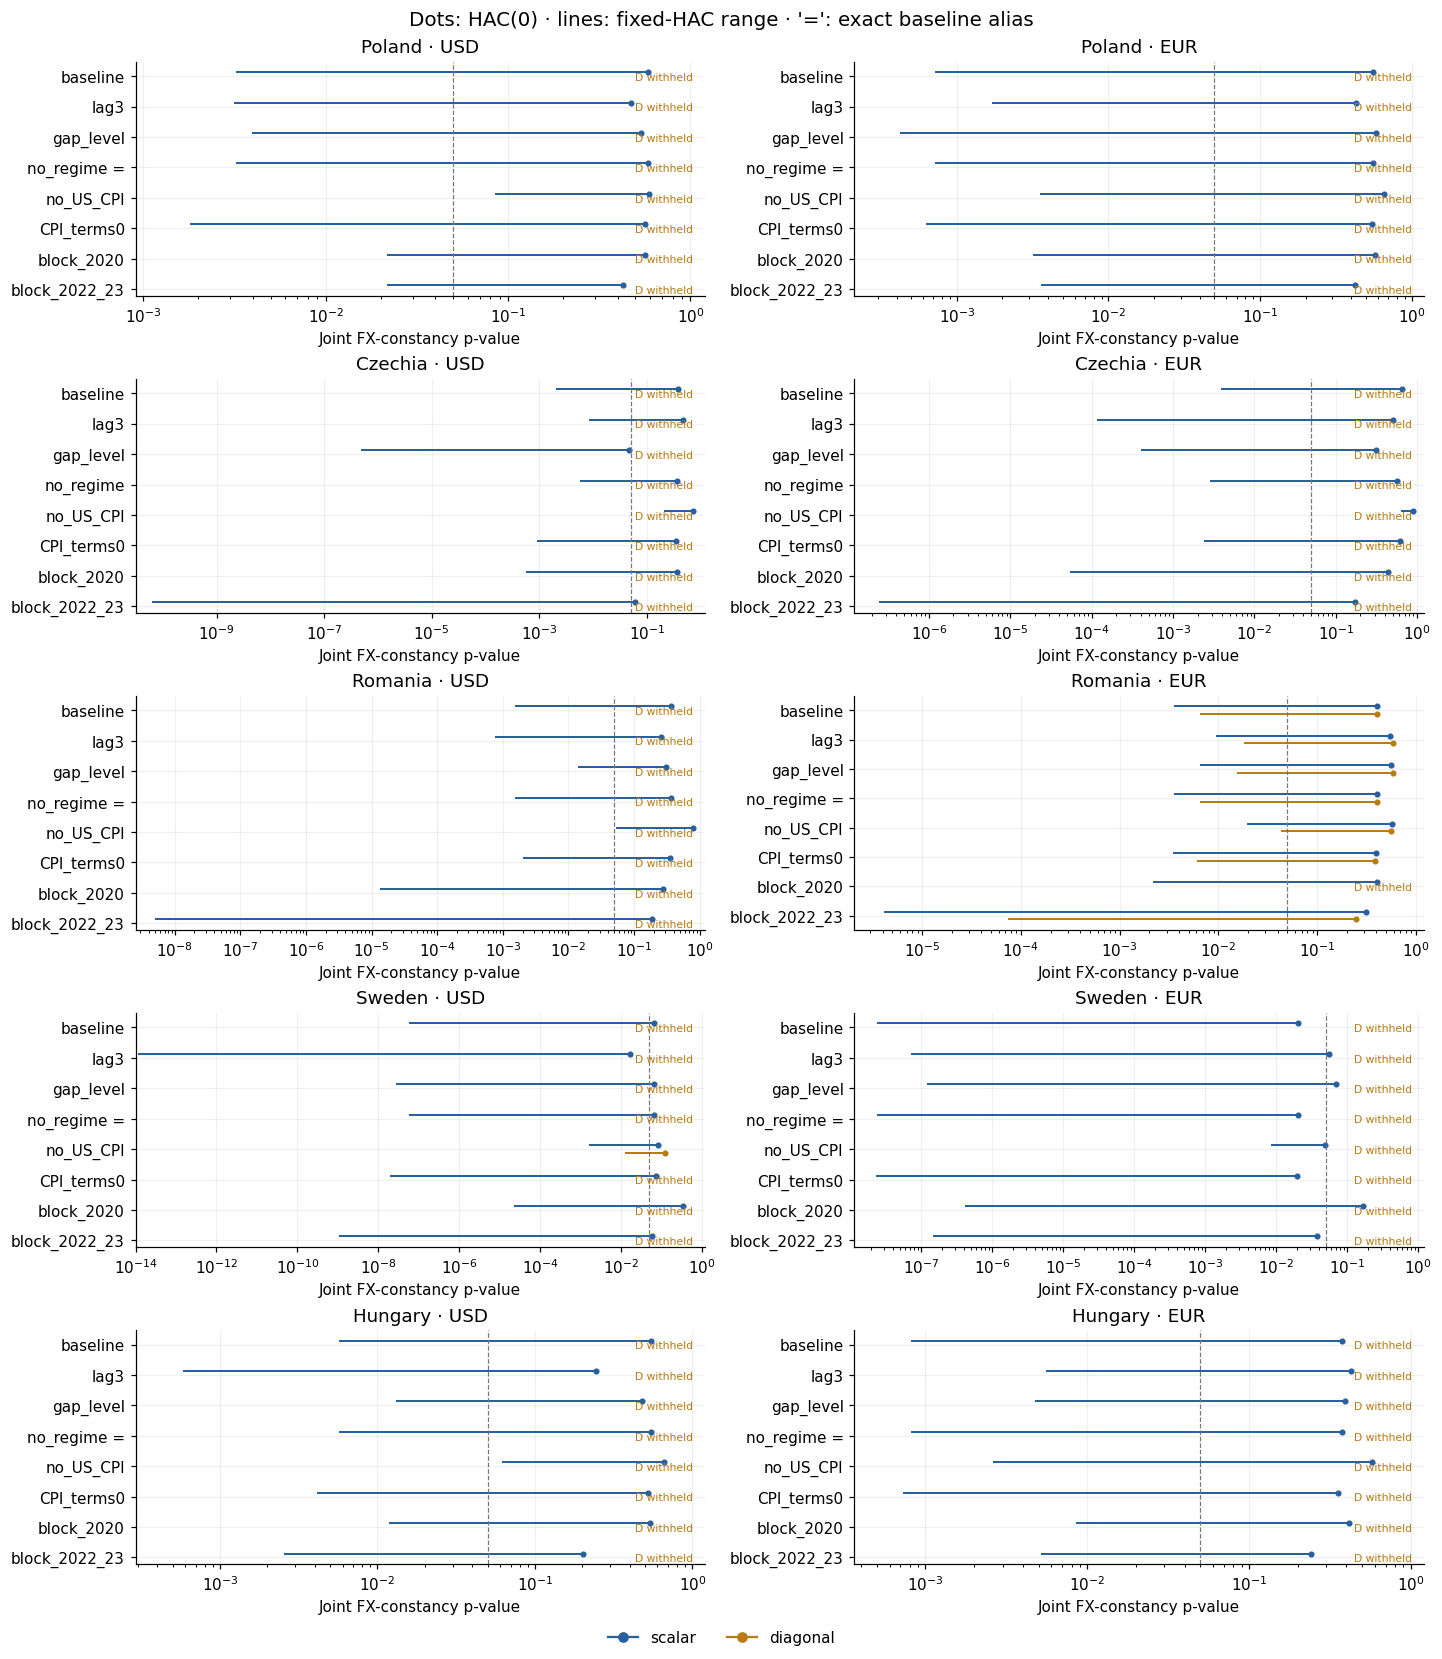

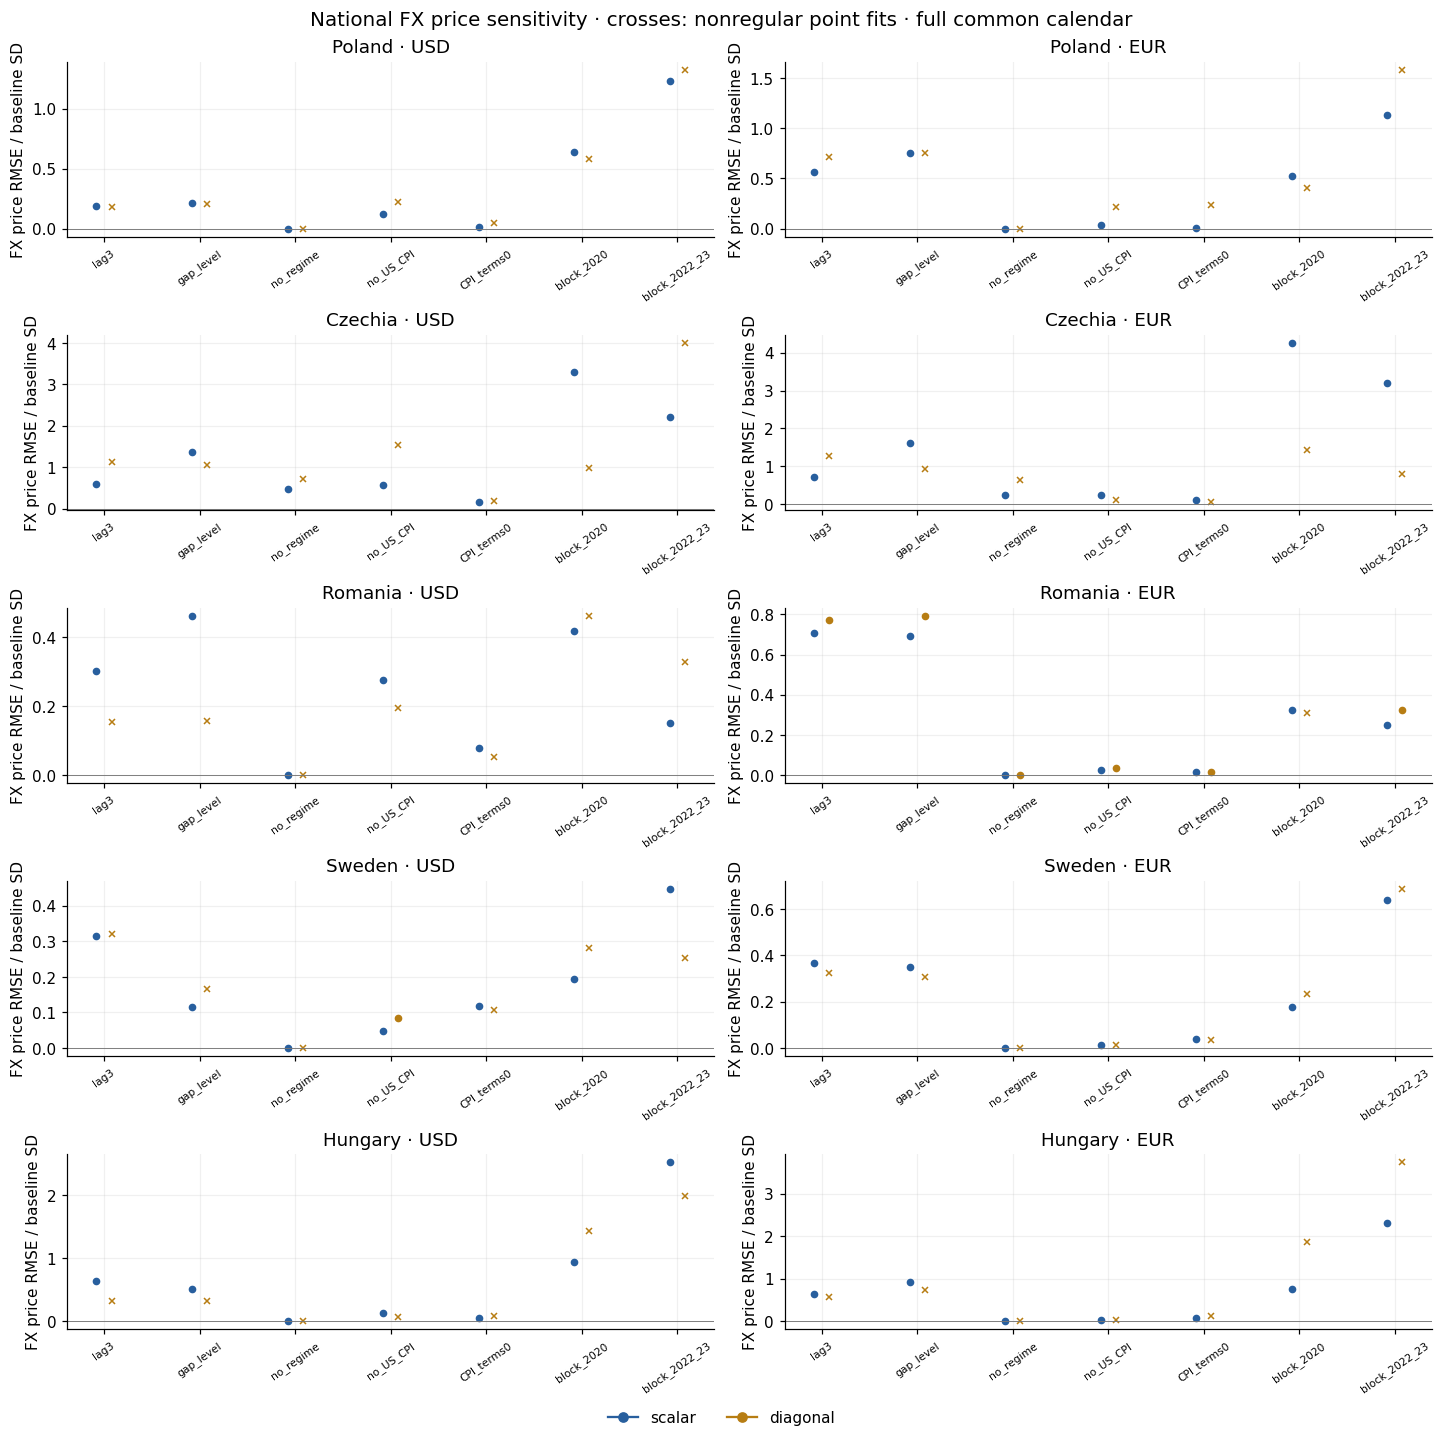

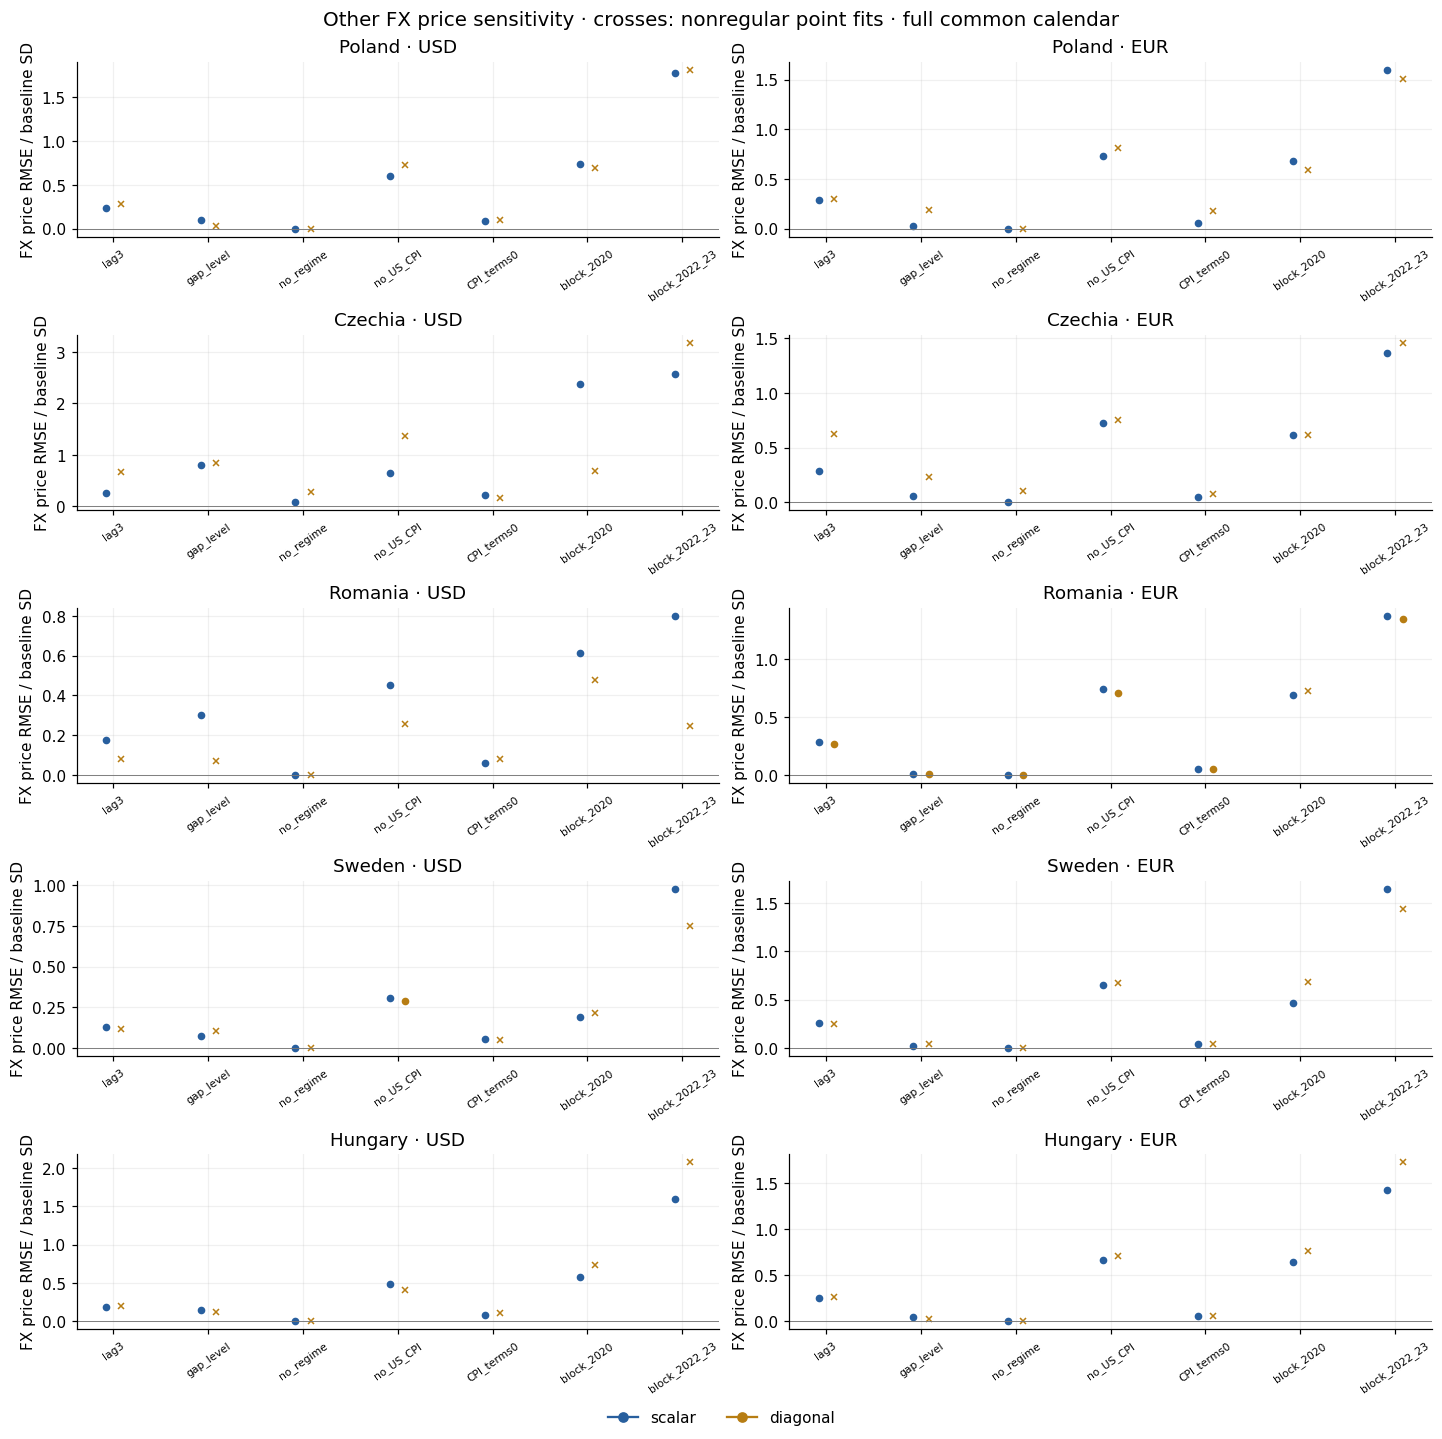

In [9]:
figure_files = []
def save_plot(name):
    plt.savefig(OUT/name, dpi=160, bbox_inches="tight", metadata={"Software": "Regional targeted robustness notebook 30"})
    figure_files.append(name); plt.show(); plt.close()
plot_colors = {"scalar": "#285f9e", "diagonal": "#b77d13"}
fig, axes = plt.subplots(5, 2, figsize=(13, 15), layout="constrained")
for row, country in enumerate(NAMES):
    for col, currency in enumerate(CURRENCIES):
        ax = axes[row, col]
        for v, variant in enumerate(VARIANTS):
            for k, cov in enumerate(COVARIANCES):
                g = summary.query("country == @country and perspective == @currency and covariance == @cov and variant == @variant").iloc[0]
                y = v+(.13 if k else -.13); color = plot_colors[cov]
                if g.available_bandwidth_tests == len(HAC_LAGS):
                    ax.hlines(y, max(g.FX_constancy_p_min, 1e-14), max(g.FX_constancy_p_max, 1e-14), color=color, lw=1.3)
                    ax.plot(max(g.FX_constancy_p_QML, 1e-14), y, marker="o", ms=3, color=color, label=cov if v == 0 else None)
                else: ax.text(.98, y, "D withheld" if k else "S withheld", transform=ax.get_yaxis_transform(), ha="right", color=color, fontsize=7)
        pmin = summary.query("country == @country and perspective == @currency").FX_constancy_p_min.min()
        lower = max(min(.02, pmin*.5), 1e-14) if np.isfinite(pmin) else .01
        ax.axvline(.05, color="#777777", ls="--", lw=.8); ax.set_xscale("log"); ax.set_xlim(lower, 1.2)
        labels = [v+(" =" if v == "no_regime" and country != "CZ" else "") for v in VARIANTS]
        ax.set(title=f"{NAMES[country]} · {currency}", yticks=range(len(VARIANTS)), yticklabels=labels, xlabel="Joint FX-constancy p-value")
        ax.invert_yaxis()
handles = [plt.Line2D([], [], color=plot_colors[c], marker="o", ls="-", label=c) for c in COVARIANCES]
fig.legend(handles=handles, loc="outside lower center", ncol=2, frameon=False)
fig.suptitle("Dots: HAC(0) · lines: fixed-HAC range · '=': exact baseline alias", fontsize=13)
save_plot("01_joint_FX_constancy_sensitivity.png")
for risk, slug in [("National FX", "national"), ("Other FX", "other")]:
    fig, axes = plt.subplots(5, 2, figsize=(13, 13), layout="constrained")
    variants = VARIANTS[1:]
    for row, country in enumerate(NAMES):
        for col, currency in enumerate(CURRENCIES):
            ax = axes[row, col]
            for v, variant in enumerate(variants):
                for k, cov in enumerate(COVARIANCES):
                    g = path_comparison.query("country == @country and perspective == @currency and covariance == @cov and variant == @variant and risk == @risk").iloc[0]
                    ready = bool(summary.query("country == @country and perspective == @currency and covariance == @cov and variant == @variant").regular_all_lags.iloc[0])
                    ax.plot(v+(.08 if k else -.08), g.RMSE_over_baseline_SD, marker="o" if ready else "x", color=plot_colors[cov], ms=4)
            ax.set(title=f"{NAMES[country]} · {currency}", ylabel="FX price RMSE / baseline SD", xticks=range(len(variants)), xticklabels=variants)
            ax.tick_params(axis="x", rotation=35, labelsize=7); ax.axhline(0, color="#777777", lw=.6)
    fig.legend(handles=handles, loc="outside lower center", ncol=2, frameon=False)
    fig.suptitle(f"{risk} price sensitivity · crosses: nonregular point fits · full common calendar", fontsize=13)
    save_plot(f"02_price_RMSE_{slug}.png")

## 9. Save all checks and the final common-sample summary

Retain all scenarios, aliases, numerical failures, actual calendar weights, raw/weighted scores,
full filtered paths, joint uncertainty, conditioning audits, residual screens and premium products.
The summary counts active checks separately from exact aliases and baseline references. Read
constancy, zero pricing, individual currency evidence and numerical adequacy separately. Missing
p-values do not mean non-rejection. Regional covariance-targeting sensitivity remains a separate task.

In [10]:
tables = {"input_audit.csv": input_audit, "reference_audit.csv": reference_audit, "implementation_checks.csv": checks,
    "conditioning_design.csv": conditioning, "raw_conditioning_features.csv": raw_features, "instrument_transform.csv": normalizers,
    "design_audit.csv": design_audit, "instrument_VIF.csv": vifs, "inflation_persistence.csv": inflation_audit,
    "inflation_quality_weights.csv": quality_flags, "scenario_applicability.csv": applicability, "start_candidate_audit.csv": start_audit,
    "starting_points.csv": starting_points, "baseline_candidate_audit.csv": baseline_audit, "baseline_refinements.csv": refinements, "nesting_audit.csv": nesting_audit,
    "fit_summary.csv": fit_summary, "inference_audit.csv": inference_audit, "inference_cache_audit.csv": inference_cache_audit,
    "restriction_tests.csv": tests, "price_coefficients.csv": coefficients, "risk_price_paths.csv": price_paths, "parameter_bounds.csv": parameter_bounds,
    "residual_diagnostics.csv": residuals, "cross_covariance_diagnostics.csv": cross, "diagnostic_summary.csv": diagnostic_summary,
    "price_path_comparison.csv": path_comparison, "premium_components.csv": premiums, "price_covariance_products.csv": product_summary, "summary.csv": summary}
for name, frame in tables.items(): frame.to_csv(OUT/name, index=False, float_format="%.17g", lineterminator=chr(10))
parameter_files = []
for key, fit in fits.items():
    case = cases[key]; f = fit["filter"]; info = fit["inference"]; name = f"parameters_{case['id']}.npz"
    np.savez(OUT/name, theta=fit["theta"], weights=case["weights"], H=f["H"], mu=f["mu"], errors=f["errors"], losses=f["losses"], scores=f["scores"],
        weighted_scores=case["weights"][:, None]*f["scores"], equity_alphas=np.zeros(3), target=f["target"], intercept=f["intercept"],
        alpha=f["alpha"], beta=f["beta"], Hessian=info["Hessian"], Hessian_small=info["Hessian_small"], **{f"covariance_HAC{h}": e["covariance"] for h, e in info["estimates"].items()})
    parameter_files.append(name)
_, after = verify_inputs()
assert input_hashes == after and engine_hashes == {n: sha((ROOT/n).read_bytes()) for n in engine_hashes}
outputs = [*tables, *figure_files, *parameter_files, *cache_files]
assert len(set(outputs)) == len(outputs)
metadata = {"notebook": "30_regional_FX_targeted_robustness.ipynb", "model_version": MODEL_VERSION, "engines": engine_hashes,
    "previous_manifest_sha256": PREVIOUS_MANIFEST_SHA, "previous": PREVIOUS.relative_to(ROOT).as_posix(), "first": str(months[0]), "last": str(months[-1]), "observations_per_state_path": len(months),
    "baseline_references": len(references), "cases": len(fits), "active_sensitivity_fits": int(sum(k[3] != "baseline" and not cases[k]["alias"] for k in cases)),
    "baseline_alias_cases": int(sum(c["alias"] for c in cases.values())), "baseline_refinements": len(refinements), "input_locks": LOCK_HASHES, "input_file_hashes": input_hashes, "spec": spec,
    "settings": {"START_DYNAMICS": START_DYNAMICS, "MAX_ITER": MAX_ITER, "MAX_ITER_OVERRIDES": {"/".join(map(str,k)): v for k,v in MAX_ITER_OVERRIDES.items()}, "HAC_LAGS": HAC_LAGS, "TEST_LAGS": TEST_LAGS},
    "python": sys.executable, "python_version": platform.python_version(), "packages": versions, "outputs": {name: sha((OUT/name).read_bytes()) for name in outputs},
    "notes": ["Frozen 144-month common sample in base; five countries, USD/EUR, scalar/diagonal BEKK", "Corrected five-series FX means; zero alphas; constant world/local, time-varying FX prices",
        "Weights select joint likelihood terms only; every observed return updates the state and derivatives", "Full-calendar weighted Hessian and score-HAC; existing numerical gates retained",
        "2008-09 outside sample; no_regime aliases outside CZ; do not count aliases as separate evidence", "No across-weight likelihood/IC ranking; exploratory tests; no hedging-cost or causal burden estimate"]}
(OUT/"estimation_manifest.json").write_text(json.dumps(metadata, indent=2, sort_keys=True)+chr(10))
display(summary.set_index(["country", "perspective", "covariance", "variant"])[["scored_months", "parameters", "baseline_alias", "inference_ready_QML", "FX_constancy_p_QML", "FX_constancy_p_min", "FX_constancy_p_max", "FX_zero_function_p_QML", "variance_flags_holm_full_path"]].round(5))
display(summary.groupby(["variant", "covariance"]).agg(cases=("country", "size"), aliases=("baseline_alias", "sum"), primary_inference_available=("inference_ready_QML", "sum"),
    eligible_all_bandwidths=("available_bandwidth_tests", lambda x: int(x.eq(len(HAC_LAGS)).sum()))))
active = summary.query("variant != 'baseline' and not baseline_alias")
display(Markdown(f"**Completed:** {len(fits)} labelled cases = {len(references)} pinned baseline references + "
    f"{metadata['active_sensitivity_fits']} active sensitivity fits + {metadata['baseline_alias_cases']} exact aliases. "
    f"Primary inference is available for **{int(active.inference_ready_QML.sum())}/{len(active)} active checks**. "
    f"Saved {len(tables)} tables and {len(figure_files)} charts in `{OUT.relative_to(ROOT)}`. "
    f"Recorded {len(refinements)} baseline consistency refinements separately; all protected inputs/earlier outputs remain unchanged."))

scored_months  parameters  \
country perspective covariance variant                                    
HU      USD         scalar     baseline                 144          30   
                               lag3                     144          30   
                               gap_level                144          30   
                               no_regime                144          30   
                               no_US_CPI                144          28   
...                                                     ...         ...   
SE      EUR         diagonal   no_regime                144          38   
                               no_US_CPI                144          37   
                               CPI_terms0               143          38   
                               block_2020               132          38   
                               block_2022_23            120          38   

                                              baseline_alias  \
country perspective covariance variant                         
HU      USD         scalar     baseline                False   
                               lag3                    False   
                               gap_level               False   
                               no_regime                True   
                               no_US_CPI               False   
...                                                      ...   
SE      EUR         diagonal   no_regime                True   
                               no_US_CPI               False   
                               CPI_terms0              False   
                               block_2020              False   
                               block_2022_23           False   

                                              inference_ready_QML  \
country perspective covariance variant                              
HU      USD         scalar     baseline                      True   
                               lag3                          True   
                               gap_level                     True   
                               no_regime                     True   
                               no_US_CPI                     True   
...                                                           ...   
SE      EUR         diagonal   no_regime                    False   
                               no_US_CPI                    False   
                               CPI_terms0                   False   
                               block_2020                   False   
                               block_2022_23                False   

                                              FX_constancy_p_QML  \
country perspective covariance variant                             
HU      USD         scalar     baseline                  0.54390   
                               lag3                      0.24588   
                               gap_level                 0.48080   
                               no_regime                 0.54390   
                               no_US_CPI                 0.65820   
...                                                          ...   
SE      EUR         diagonal   no_regime                     NaN   
                               no_US_CPI                     NaN   
                               CPI_terms0                    NaN   
                               block_2020                    NaN   
                               block_2022_23                 NaN   

                                              FX_constancy_p_min  \
country perspective covariance variant                             
HU      USD         scalar     baseline                  0.00573   
                               lag3                      0.00058   
                               gap_level                 0.01318   
                               no_regime                 0.00573   
                               no_US_CPI      

cases  aliases  primary_inference_available  \
variant       covariance                                                
CPI_terms0    diagonal       10        0                            1   
              scalar         10        0                           10   
baseline      diagonal       10        0                            1   
              scalar         10        0                           10   
block_2020    diagonal       10        0                            0   
              scalar         10        0                           10   
block_2022_23 diagonal       10        0                            1   
              scalar         10        0                           10   
gap_level     diagonal       10        0                            1   
              scalar         10        0                           10   
lag3          diagonal       10        0                            1   
              scalar         10        0                           10   
no_US_CPI     diagonal       10        0                            2   
              scalar         10        0                           10   
no_regime     diagonal       10        8                            1   
              scalar         10        8                           10   

                          eligible_all_bandwidths  
variant       covariance                           
CPI_terms0    diagonal                          1  
              scalar                           10  
baseline      diagonal                          1  
              scalar                           10  
block_2020    diagonal                          0  
              scalar                           10  
block_2022_23 diagonal                          1  
              scalar                           10  
gap_level     diagonal                          1  
              scalar                           10  
lag3          diagonal                          1  
              scalar                           10  
no_US_CPI     diagonal                          2  
              scalar                           10  
no_regime     diagonal                          1  
              scalar                           10

**Completed:** 160 labelled cases = 20 pinned baseline references + 124 active sensitivity fits + 16 exact aliases. Primary inference is available for **68/124 active checks**. Saved 30 tables and 3 charts in `output/30_regional_FX_targeted_robustness/2014-10_2026-09/targeted_e11bdda3`. Recorded 0 baseline consistency refinements separately; all protected inputs/earlier outputs remain unchanged.

## Reading the recorded frozen run

These observations describe the fixed sensitivity set on October 2014–September 2026; all pricing p-values remain exploratory.

- **Inference availability:** all **62 scalar active checks** are regular at the primary bandwidth; only **6 of 62 diagonal active checks** pass the numerical gates. The other **56 diagonal checks** retain point fits but have ordinary tests and bands withheld. Baselines and exact aliases are counted separately.
- **Sweden is sensitive to specification and crisis influence.** For EUR/scalar, joint FX-constancy p-values move from **0.0203** at baseline to **0.0549** with lag-3 inflation, **0.0691** with national gap levels, and **0.1686** with 2020 likelihood terms zeroed. The carried-CPI-date check remains **0.0201**. For USD/scalar, lag-3 timing instead changes the baseline **0.0680** to **0.0168**. No uniform robustness claim follows.
- **Other primary evidence is weak or isolated.** Hungary, Poland and Romania have no 5% joint FX-constancy rejection in the scalar active checks. Czechia has one: USD with the persistent national gap-level alternative (**0.0462**), which remains exploratory. The full four-bandwidth tables show substantial HAC sensitivity; a non-rejection is not proof of constant prices or zero FX pricing.

All predictor-deletion and scalar-to-diagonal likelihood bounds passed without changing any baseline. The 2020 and 2022–23 exercises preserve every observed innovation and covariance update; they measure likelihood influence, not returns in a crisis-free sample. The next research extension is regional covariance-targeting sensitivity.